# 03. Feature Engineering & Preprocessing Pipeline

## 1. Underwriting Domain Rationale & Feature Strategy
In algorithmic credit risk modeling, raw bureau variables (such as total loan amount, monthly installment, or revolving balance) fail to capture an applicant's true repayment capacity unless contextualized against their **cash flow**, **debt service obligations**, and **credit file seasoning**.

### Key Feature Engineering Goals:
1. **Debt Burden & Capacity Ratios**:
   - **`loan_to_income`**: Total requested principal relative to annual gross earnings.
   - **`installment_to_income`**: Annualized installment burden as a fraction of annual income (`installment * 12 / annual_inc`).
   - **`revol_bal_to_income`**: Outstanding credit card revolving debt relative to annual earnings.
2. **Credit Seasoning & Maturity**:
   - **`credit_history_years`**: Elapsed time between the applicant's earliest credit line opening and loan issuance.
3. **Monotonic Rating Transformations**:
   - **`sub_grade_ord`**: Ordinal mapping of 35 sub-grades (`A1`=1 to `G5`=35) preserving monotonic risk without one-hot dimensionality explosion.
   - **`grade_ord`**: Ordinal mapping of Grades (`A`=1 to `G`=7).
4. **Non-Linear Liquidity & Velocity Stress Flags**:
   - **`high_utilization_flag`**: Borrowers utilizing $\ge 80\%$ of revolving limits.
   - **`high_dti_flag`**: Borrowers with non-mortgage debt service $\ge 20\%$ of income.
   - **`velocity_hazard_flag`**: Borrowers with $\ge 2$ recent credit inquiries.
   - **`derogatory_flag`**: Borrowers with public derogatories or bankruptcies.
5. **Production Preprocessing Pipeline (`Pipeline` & `ColumnTransformer`)**:
   - Standard scaling for linear models vs passthrough for gradient boosted trees.
   - Strict data leakage prevention across train/validation splits.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import (
    DomainFeatureExtractor,
    engineer_features_df,
    build_preprocessor,
    build_feature_pipeline,
    get_feature_groups,
    RAW_NUMERICAL_COLS,
    NOMINAL_CATEGORICAL_COLS,
    ENGINEERED_FEATURE_NAMES
)

# Global visualization styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.titlesize': 15,
    'figure.dpi': 120,
})

data_path = PROJECT_ROOT / 'data' / 'processed' / 'loans_cleaned.parquet'
df = pd.read_parquet(data_path)
print(f'Loaded cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
X = df.drop(columns=['target'])
y = df['target']

Loaded cleaned dataset: 38,577 rows x 25 columns


## 2. Domain Feature Extraction & Engineering

We execute `DomainFeatureExtractor` to compute financial leverage, burden, and credit file maturity metrics.

In [2]:
extractor = DomainFeatureExtractor(drop_original_dates=True, drop_raw_grades=True)
X_eng = extractor.fit_transform(X)

print(f'Transformed feature matrix shape: {X_eng.shape[0]:,} rows x {X_eng.shape[1]} columns')
print('\nNewly engineered features summary:')
print(X_eng[ENGINEERED_FEATURE_NAMES].describe().round(3).T[['mean', 'std', 'min', '50%', 'max']])

Transformed feature matrix shape: 38,577 rows x 31 columns

Newly engineered features summary:
                         mean    std    min     50%     max
credit_history_years   13.722  6.831  2.998  12.498  65.413
loan_to_income          0.186  0.115  0.001   0.163   0.830
installment_to_income   0.066  0.040  0.000   0.058   0.320
revol_bal_to_income     0.202  0.187  0.000   0.157   3.116
log_annual_inc         10.969  0.560  8.294  10.983  15.607
sub_grade_ord          10.819  6.768  1.000  10.000  35.000
grade_ord               2.553  1.380  1.000   2.000   7.000
high_utilization_flag   0.173  0.378  0.000   0.000   1.000
high_dti_flag           0.187  0.390  0.000   0.000   1.000
velocity_hazard_flag    0.239  0.426  0.000   0.000   1.000
derogatory_flag         0.054  0.225  0.000   0.000   1.000


## 3. Correlation Uplift with Default Target

Let us examine how the newly engineered ratios and ordinal scores compare against raw input features in linear association with loan default.

=== CORRELATION WITH DEFAULT (TARGET = 1) ===
int_rate                  [RAW]          : +0.2114
sub_grade_ord             [ENGINEERED]   : +0.2053
term                      [RAW]          : +0.1735
loan_to_income            [ENGINEERED]   : +0.1181
revol_util                [RAW]          : +0.0999
installment_to_income     [ENGINEERED]   : +0.0837
high_utilization_flag     [ENGINEERED]   : +0.0709
loan_amnt                 [RAW]          : +0.0595
velocity_hazard_flag      [ENGINEERED]   : +0.0563
derogatory_flag           [ENGINEERED]   : +0.0538
dti                       [RAW]          : +0.0451
installment               [RAW]          : +0.0272
credit_history_years      [ENGINEERED]   : -0.0157
annual_inc                [RAW]          : -0.0409


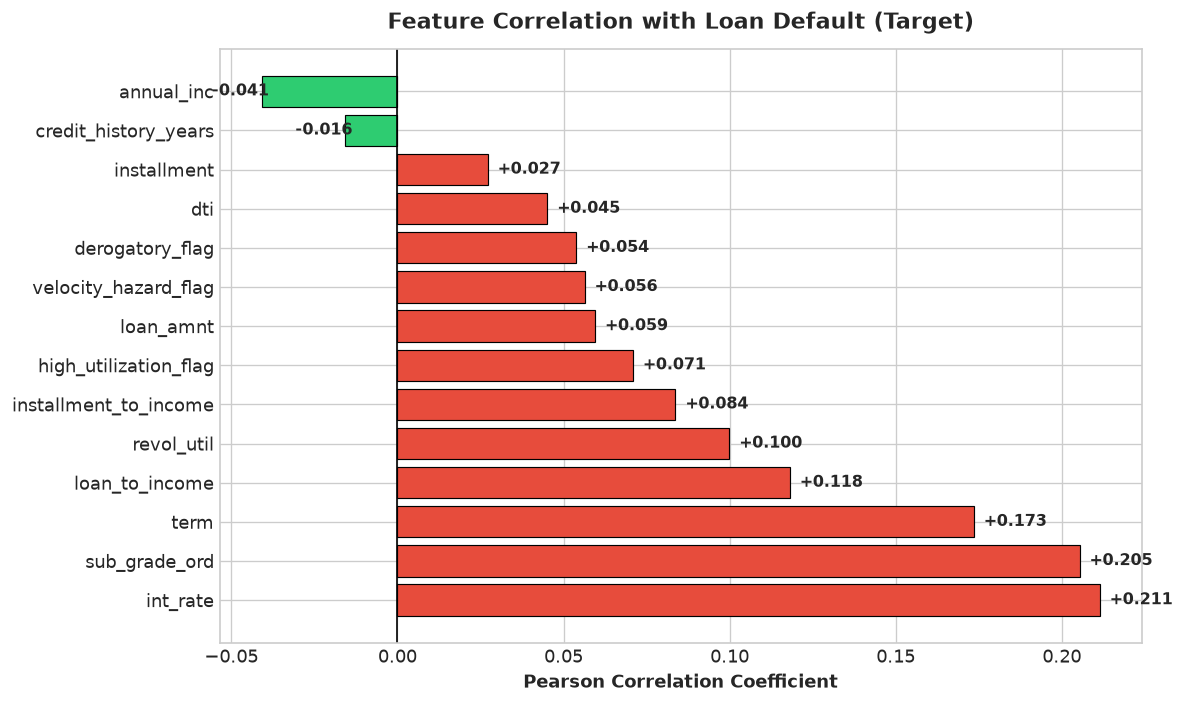

In [3]:
df_engineered = X_eng.copy()
df_engineered['target'] = y.values

feature_subset = [
    'int_rate', 'sub_grade_ord', 'term', 'loan_to_income',
    'revol_util', 'installment_to_income', 'high_utilization_flag',
    'loan_amnt', 'installment', 'annual_inc', 'velocity_hazard_flag',
    'derogatory_flag', 'dti', 'credit_history_years'
]

corr_series = df_engineered[feature_subset + ['target']].corr()['target'].drop('target').sort_values(ascending=False)

print('=== CORRELATION WITH DEFAULT (TARGET = 1) ===')
for feat, val in corr_series.items():
    tag = '[ENGINEERED]' if feat in ENGINEERED_FEATURE_NAMES else '[RAW]'
    print(f'{feat:<25} {tag:<14} : {val:+.4f}')

# Correlation Barplot
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c' if c > 0 else '#2ecc71' for c in corr_series.values]
bars = ax.barh(corr_series.index, corr_series.values, color=colors, edgecolor='black', linewidth=0.7)
ax.set_title('Feature Correlation with Loan Default (Target)', fontweight='bold', pad=12)
ax.set_xlabel('Pearson Correlation Coefficient', fontweight='bold')
ax.axvline(0, color='black', linewidth=1)
for bar, val in zip(bars, corr_series.values):
    offset = 0.003 if val >= 0 else -0.015
    ax.text(val + offset, bar.get_y() + bar.get_height()/2, f'{val:+.3f}', va='center', fontweight='bold', fontsize=9.5)
plt.tight_layout()
plt.show()

## 4. Deep-Dive: Loan-to-Income Decile Default Curves

In credit risk, debt-burden ratios often display non-linear risk tipping points. Let us partition borrowers into `loan_to_income` deciles and plot empirical default rates.

C:\Users\dr_ra\AppData\Local\Temp\ipykernel_26968\164382248.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  decile_stats = df_engineered.groupby('lti_decile').agg(


=== LOAN-TO-INCOME DECILE RISK PROFILE ===
            loan_count  default_rate_pct  median_lti
lti_decile                                          
D1                3860             10.75        0.04
D2                3860             11.84        0.07
D3                3853             11.58        0.10
D4                3858             11.28        0.12
D5                3858             12.44        0.15
D6                3867             13.47        0.18
D7                3849             14.99        0.21
D8                3861             15.95        0.25
D9                3854             19.17        0.31
D10               3857             24.40        0.41


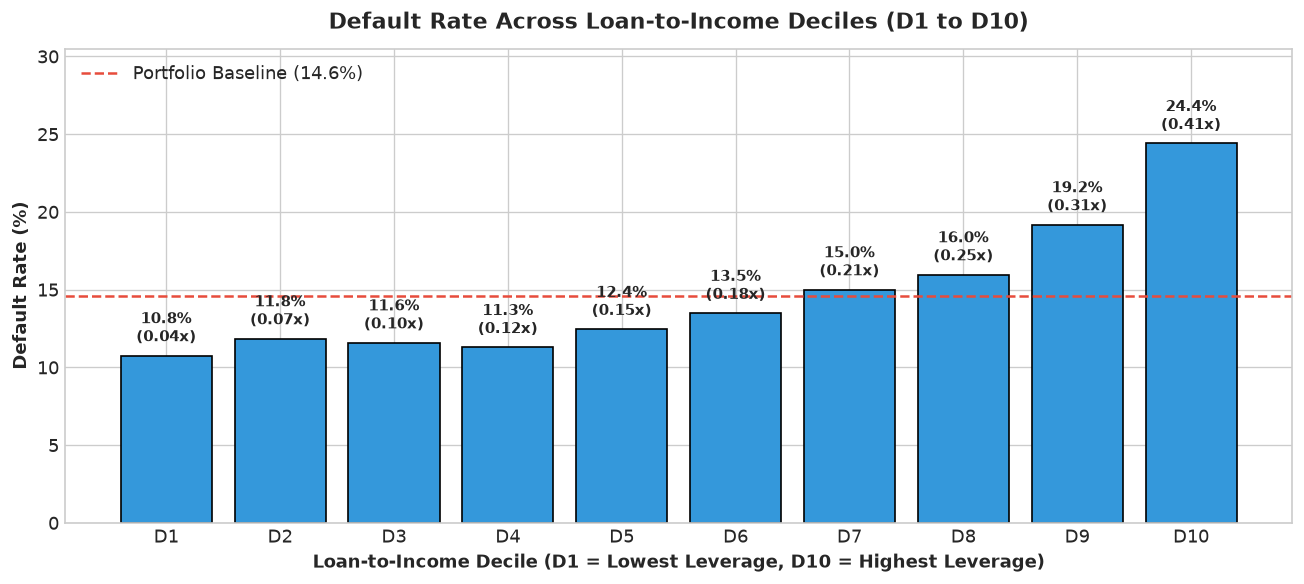

In [4]:
df_engineered['lti_decile'] = pd.qcut(df_engineered['loan_to_income'], q=10, labels=[f'D{i+1}' for i in range(10)])
decile_stats = df_engineered.groupby('lti_decile').agg(
    loan_count=('target', 'count'),
    default_rate_pct=('target', lambda x: x.mean() * 100),
    median_lti=('loan_to_income', 'median')
)

print('=== LOAN-TO-INCOME DECILE RISK PROFILE ===')
print(decile_stats.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(decile_stats.index, decile_stats['default_rate_pct'], color='#3498db', edgecolor='black', linewidth=1)
ax.axhline(df['target'].mean() * 100, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Portfolio Baseline ({df["target"].mean()*100:.1f}%)')
ax.set_title('Default Rate Across Loan-to-Income Deciles (D1 to D10)', fontweight='bold', pad=12)
ax.set_xlabel('Loan-to-Income Decile (D1 = Lowest Leverage, D10 = Highest Leverage)', fontweight='bold')
ax.set_ylabel('Default Rate (%)', fontweight='bold')
ax.set_ylim(0, max(decile_stats['default_rate_pct']) * 1.25)
ax.legend(loc='upper left')
for bar, rate, med in zip(bars, decile_stats['default_rate_pct'], decile_stats['median_lti']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.6, f'{rate:.1f}%\n({med:.2f}x)', ha='center', va='bottom', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

## 5. End-to-End Scikit-Learn Preprocessing Pipeline

We construct and validate the production-ready `Pipeline` incorporating both `DomainFeatureExtractor` and `ColumnTransformer`.
Two pipeline variants are available:
- **Scaled Pipeline (`scale_numeric=True`)**: Standardizes numerical features (z-score scaling) for distance/linear models (Logistic Regression, ElasticNet).
- **Unscaled Pipeline (`scale_numeric=False`)**: Preserves raw feature scales for tree-based ensemble models (LightGBM, XGBoost).

In [5]:
pipeline_scaled, num_feature_names = build_feature_pipeline(scale_numeric=True)
pipeline_unscaled, _ = build_feature_pipeline(scale_numeric=False)

print('=== PREPROCESSING PIPELINE ARCHITECTURE ===')
print(pipeline_scaled)

# Fit-transform test on full dataset
X_trans_scaled = pipeline_scaled.fit_transform(X)
X_trans_unscaled = pipeline_unscaled.fit_transform(X)

col_transformer = pipeline_scaled.named_steps['preprocessor']
output_feature_names = col_transformer.get_feature_names_out()

print(f'\nOriginal input columns:             {X.shape[1]}')
print(f'Intermediate engineered features:   {len(num_feature_names)}')
print(f'Final preprocessed matrix shape:    {X_trans_scaled.shape}')
print(f'Final total output features:        {len(output_feature_names)}')
print('\nSample output feature names (first 15):')
print(output_feature_names[:15])

=== PREPROCESSING PIPELINE ARCHITECTURE ===
Pipeline(steps=[('domain_features', DomainFeatureExtractor()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['loan_amnt', 'term',
                                                   'int_rate', 'installment',
                                                   'annual_inc', 'dti',
                                                   'delinq_2yrs',
                                                   'inq_last_6mths', 'open_acc',
                                                   'pub_rec', 'revol_bal',
                                                   'revol_util', 'total_acc',
                                                   'pub_rec_bankruptcies',
                                                   'emp_length_years',
                                                   'emp_length_missing',
                                            


Original input columns:             24
Intermediate engineered features:   27
Final preprocessed matrix shape:    (38577, 98)
Final total output features:        98

Sample output feature names (first 15):
['loan_amnt' 'term' 'int_rate' 'installment' 'annual_inc' 'dti'
 'delinq_2yrs' 'inq_last_6mths' 'open_acc' 'pub_rec' 'revol_bal'
 'revol_util' 'total_acc' 'pub_rec_bankruptcies' 'emp_length_years']


## 6. Production Inference Simulation (Single Loan Application)

To guarantee that our pipeline is production-ready for the Streamlit underwriting application (`app/streamlit_app.py`), we simulate passing a single applicant record through the pipeline.

In [6]:
sample_applicant = X.iloc[[0]].copy()
print('Raw applicant record (sample attributes):')
for col in ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'annual_inc', 'dti', 'home_ownership', 'purpose']:
    print(f'  {col:<22}: {sample_applicant[col].values[0]}')

# Transform single applicant record
applicant_features = pipeline_scaled.transform(sample_applicant)
print(f'\nTransformed applicant feature vector shape: {applicant_features.shape}')
print('Zero NaNs or infinities:', not np.isnan(applicant_features).any() and not np.isinf(applicant_features).any())
print('\nPipeline is certified production-ready for Step 6 (Model Training & Evaluation)!')

Raw applicant record (sample attributes):
  loan_amnt             : 5000
  term                  : 36
  int_rate              : 10.65
  installment           : 162.87
  grade                 : B
  sub_grade             : B2
  annual_inc            : 24000.0
  dti                   : 27.65
  home_ownership        : RENT
  purpose               : credit_card

Transformed applicant feature vector shape: (1, 98)
Zero NaNs or infinities: True

Pipeline is certified production-ready for Step 6 (Model Training & Evaluation)!
